# 04 — Relações entre Variáveis

Até aqui estudamos **uma variável de cada vez**. Mas as perguntas mais interessantes envolvem **duas ou mais**: contas maiores rendem gorjetas maiores? Fumantes vão mais ao jantar? E, no ML, a pergunta central é sempre: **os atributos dizem alguma coisa sobre o alvo?**

Neste notebook vamos:
- Visualizar relações com o **gráfico de dispersão**
- Medir relações lineares com a **covariância** e a **correlação de Pearson**
- Ver os limites da correlação com o **quarteto de Anscombe**
- Usar a **correlação de Spearman** para relações monotônicas e dados com outliers
- Relacionar duas variáveis categóricas com **tabelas de contingência**
- Entender por que **correlação não é causalidade**
- Encontrar o **paradoxo de Simpson** nos pinguins

## 1. Importando bibliotecas e carregando os dados

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

pd.set_option("display.precision", 3)
plt.rcParams["figure.dpi"] = 100

gorjetas = sns.load_dataset("tips")
gorjetas["percentual"] = gorjetas["tip"] / gorjetas["total_bill"] * 100
pinguins = sns.load_dataset("penguins").dropna()

## 2. O gráfico de dispersão

O **gráfico de dispersão** (*scatter plot*) coloca uma variável em cada eixo e desenha um ponto por observação. É o primeiro gráfico a fazer quando queremos ver a relação entre duas variáveis numéricas.

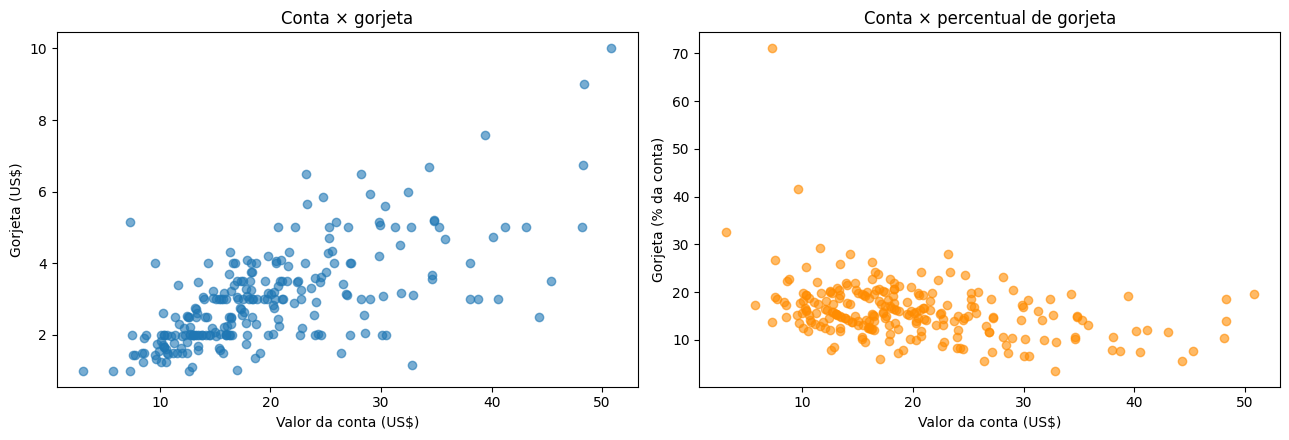

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# alpha deixa os pontos semitransparentes: onde vários se sobrepõem, a cor fica mais forte.
axes[0].scatter(gorjetas["total_bill"], gorjetas["tip"], alpha=0.6)
axes[0].set_xlabel("Valor da conta (US$)")
axes[0].set_ylabel("Gorjeta (US$)")
axes[0].set_title("Conta × gorjeta")

axes[1].scatter(gorjetas["total_bill"], gorjetas["percentual"], alpha=0.6, color="darkorange")
axes[1].set_xlabel("Valor da conta (US$)")
axes[1].set_ylabel("Gorjeta (% da conta)")
axes[1].set_title("Conta × percentual de gorjeta")
plt.tight_layout()
plt.show()

**Conclusão:** à esquerda, os pontos formam uma "nuvem" inclinada para cima: contas maiores tendem a vir com gorjetas maiores. A relação não é perfeita (com uma conta de US\$ 30, há gorjetas de pouco mais de US\$ 1 até US\$ 6), e a nuvem fica **mais espalhada** à medida que a conta cresce.

À direita, o **percentual** tende a **cair** levemente quando a conta aumenta, e os valores mais extremos (como o de 71%) aparecem nas contas pequenas, como já tínhamos visto no notebook 02.

## 🎓 Conceito: covariância

A **covariância** mede se duas variáveis **variam juntas**. Para cada mesa, multiplicamos o desvio da conta em relação à sua média pelo desvio da gorjeta em relação à sua média:

$$\text{cov}(x, y) = \frac{1}{n-1}\sum_{i=1}^{n} (x_i - \bar{x})(y_i - \bar{y})$$

- Se contas **acima** da média costumam vir com gorjetas **acima** da média (e abaixo com abaixo), os produtos são quase todos **positivos** → covariância positiva.
- Se uma sobe quando a outra desce, os produtos são negativos → covariância negativa.
- Se não há padrão, os produtos positivos e negativos se cancelam → covariância perto de zero.

Repare que a variância do notebook 02 é a covariância de uma variável **com ela mesma**.

**O problema da covariância:** o valor depende das **unidades**. Medir as gorjetas em centavos em vez de dólares multiplica a covariância por 100, sem que a relação mude nada. Por isso, ela é difícil de interpretar sozinha.

In [3]:
x = gorjetas["total_bill"].to_numpy()
y = gorjetas["tip"].to_numpy()

# Covariância à mão: produto dos desvios, somado e dividido por n - 1.
cov_mao = np.sum((x - x.mean()) * (y - y.mean())) / (len(x) - 1)
# np.cov devolve uma matriz 2×2: [[var(x), cov(x,y)], [cov(y,x), var(y)]]; [0, 1] pega a covariância.
print(f"Covariância à mão: {cov_mao:.3f}    np.cov: {np.cov(x, y)[0, 1]:.3f}")
print(f"Gorjeta em centavos:   {np.cov(x, y * 100)[0, 1]:.1f}   (100 vezes maior, mesma relação!)")

Covariância à mão: 8.324    np.cov: 8.324
Gorjeta em centavos:   832.4   (100 vezes maior, mesma relação!)


## 🎓 Conceito: correlação de Pearson

A **correlação de Pearson** ($r$) resolve o problema das unidades dividindo a covariância pelos dois desvios padrão:

$$r = \frac{\text{cov}(x, y)}{s_x \cdot s_y}$$

O resultado fica sempre entre **−1 e +1**:
- **+1:** relação linear perfeita e crescente (os pontos formam uma reta subindo).
- **−1:** relação linear perfeita e decrescente.
- **0:** nenhuma relação **linear**.

Uma referência informal: |r| < 0,3 é fraca; entre 0,3 e 0,7, moderada; acima de 0,7, forte. Mas, como veremos, o número sozinho pode enganar.

Uma propriedade útil: $r^2$ é a fração da variação de $y$ que uma **reta** consegue explicar a partir de $x$. É o mesmo **R²** do ML-01, para uma regressão com um único atributo (notebook 14).

In [4]:
r_mao = cov_mao / (x.std(ddof=1) * y.std(ddof=1))
# stats.pearsonr devolve a correlação e um p-valor (notebook 12); .statistic pega só a correlação.
print(f"Correlação à mão: {r_mao:.3f}    scipy: {stats.pearsonr(x, y).statistic:.3f}")
print(f"Com a gorjeta em centavos: {stats.pearsonr(x, y * 100).statistic:.3f}   (não muda!)")
print(f"r² = {r_mao ** 2:.3f}")

Correlação à mão: 0.676    scipy: 0.676
Com a gorjeta em centavos: 0.676   (não muda!)
r² = 0.457


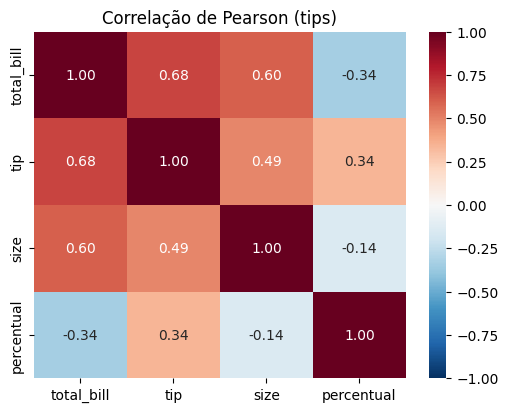

In [5]:
# A matriz de correlação: a correlação de cada par de colunas numéricas.
colunas = ["total_bill", "tip", "size", "percentual"]
matriz = gorjetas[colunas].corr()   # Pearson é o padrão do pandas

# heatmap desenha a matriz com cores; annot=True escreve os números; vmin/vmax fixam a escala em [-1, 1].
fig, ax = plt.subplots(figsize=(6, 4.5))
sns.heatmap(matriz, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, ax=ax)
ax.set_title("Correlação de Pearson (tips)")
plt.show()

**Conclusão:** a correlação entre conta e gorjeta é **0,676** (moderada a forte), e o cálculo à mão bate com o do scipy. Medir a gorjeta em centavos multiplicou a covariância por 100 (de 8,32 para **832,4**), mas a correlação **não mudou**. O $r^2 = 0{,}457$ diz que uma reta baseada na conta explica cerca de **46%** da variação das gorjetas.

Na matriz: a conta também se relaciona com o tamanho da mesa (**0,60**), o que faz sentido (mais pessoas, mais pratos). E o percentual tem correlação **−0,34** com a conta: em média, contas maiores recebem um percentual um pouco menor, a tendência de queda do gráfico da direita.

## 3. O que a correlação não enxerga: o quarteto de Anscombe

Em 1973, o estatístico Francis Anscombe criou quatro pequenos conjuntos de dados para mostrar por que **gráficos são indispensáveis**. O seaborn traz esses dados.

         média x  média y  desvio x  desvio y  correlação
dataset                                                  
I            9.0    7.501     3.317     2.032       0.816
II           9.0    7.501     3.317     2.032       0.816
III          9.0    7.500     3.317     2.030       0.816
IV           9.0    7.501     3.317     2.031       0.817


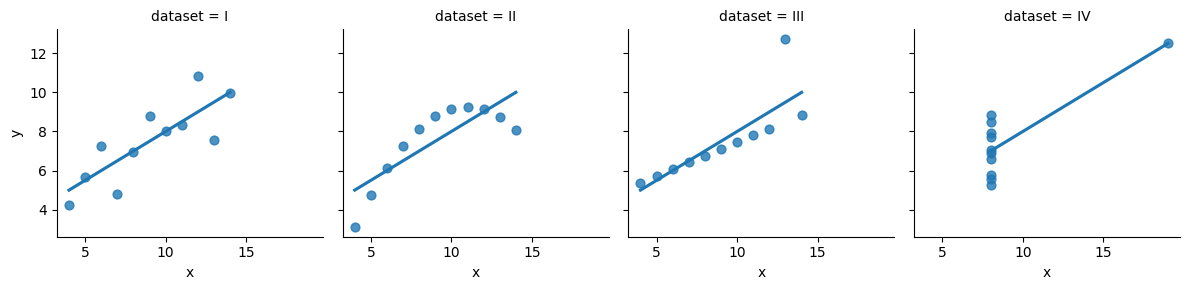

In [6]:
anscombe = sns.load_dataset("anscombe")

# Para cada conjunto (I, II, III, IV): médias, desvios e a correlação entre x e y.
# Uma função passada para .apply recebe cada grupo como um pequeno DataFrame.
def resumir(grupo):
    return pd.Series({
        "média x": grupo["x"].mean(), "média y": grupo["y"].mean(),
        "desvio x": grupo["x"].std(), "desvio y": grupo["y"].std(),
        "correlação": grupo["x"].corr(grupo["y"]),
    })

print(anscombe.groupby("dataset").apply(resumir, include_groups=False))

# lmplot com col="dataset" desenha um gráfico de dispersão (com a reta de tendência) para cada conjunto.
grade = sns.lmplot(data=anscombe, x="x", y="y", col="dataset", ci=None, height=3, scatter_kws={"s": 40})
plt.show()

**Conclusão:** os quatro conjuntos têm praticamente **os mesmos números**: média de x = 9,0, média de y ≈ 7,50, os mesmos desvios e correlação **0,816**. Mas os gráficos contam quatro histórias diferentes:
- **I:** uma relação linear com ruído, o caso em que a correlação descreve bem os dados.
- **II:** uma **curva** perfeita; a reta é o modelo errado.
- **III:** uma reta perfeita estragada por **um outlier**.
- **IV:** x é sempre 8, exceto por **um único ponto** em x = 19, que sozinho cria toda a "correlação".

Mais uma vez: **olhe os dados** antes de confiar num número.

## 🎓 Conceito: correlação de Spearman

A **correlação de Spearman** ($\rho$, "rô") é a correlação de Pearson calculada sobre os **postos** (*ranks*) dos valores, e não sobre os valores em si: o menor valor vira 1, o segundo menor vira 2, e assim por diante.

Duas consequências:
- Ela mede relações **monotônicas** (sempre crescentes ou sempre decrescentes), mesmo que **não sejam retas**: se $y$ sempre aumenta quando $x$ aumenta, $\rho = 1$, qualquer que seja a curva.
- Ela é **robusta a outliers**, porque um valor gigante vira apenas "o maior posto", não importa quão grande ele seja. É a mesma ideia de robustez da mediana.

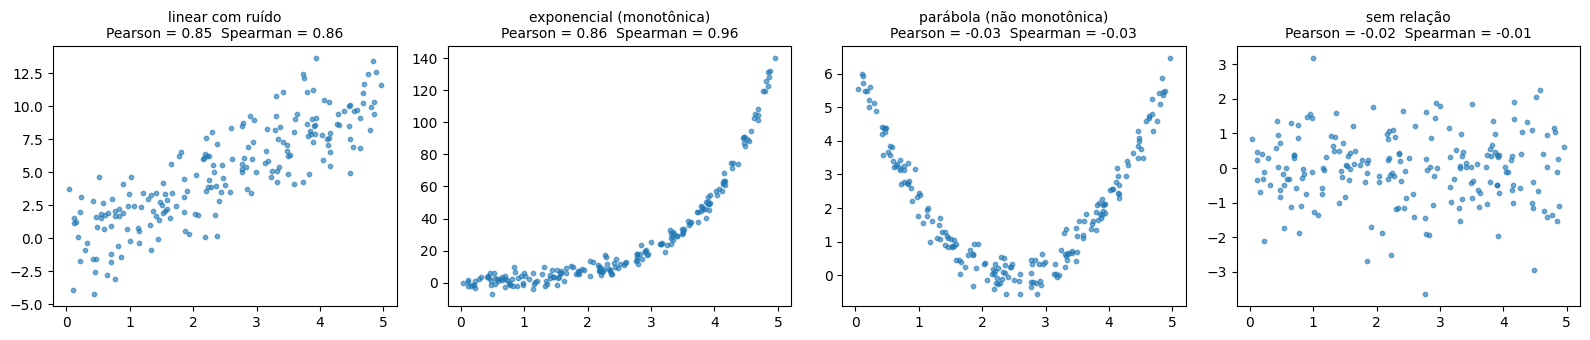

In [7]:
rng = np.random.default_rng(42)
x_sim = rng.uniform(0, 5, 200)

# Quatro relações simuladas para comparar Pearson e Spearman.
relacoes = {
    "linear com ruído": 2 * x_sim + rng.normal(0, 2, 200),
    "exponencial (monotônica)": np.exp(x_sim) + rng.normal(0, 3, 200),
    "parábola (não monotônica)": (x_sim - 2.5) ** 2 + rng.normal(0, 0.3, 200),
    "sem relação": rng.normal(0, 1, 200),
}

fig, axes = plt.subplots(1, 4, figsize=(16, 3.5))
for ax, (nome, y_sim) in zip(axes, relacoes.items()):
    pearson = stats.pearsonr(x_sim, y_sim).statistic
    spearman = stats.spearmanr(x_sim, y_sim).statistic
    ax.scatter(x_sim, y_sim, s=10, alpha=0.6)
    ax.set_title(f"{nome}\nPearson = {pearson:.2f}  Spearman = {spearman:.2f}", fontsize=10)
plt.tight_layout()
plt.show()

In [8]:
# Postos "à mão" para ver o que o Spearman faz: rankdata dá o posto de cada valor.
pequeno = np.array([10, 20, 30, 40, 1000])
print("Valores:", pequeno, "→ postos:", stats.rankdata(pequeno))

# Robustez: acrescentar uma mesa absurda (conta de US$ 5, gorjeta de US$ 100) aos dados do tips.
x_out = np.append(x, 5)       # np.append devolve um novo vetor com o valor acrescentado no final
y_out = np.append(y, 100)
print(f"\nPearson  conta × gorjeta: {stats.pearsonr(x, y).statistic:.3f} → com a mesa absurda: {stats.pearsonr(x_out, y_out).statistic:.3f}")
print(f"Spearman conta × gorjeta: {stats.spearmanr(x, y).statistic:.3f} → com a mesa absurda: {stats.spearmanr(x_out, y_out).statistic:.3f}")

Valores: [  10   20   30   40 1000] → postos: [1. 2. 3. 4. 5.]

Pearson  conta × gorjeta: 0.676 → com a mesa absurda: 0.043
Spearman conta × gorjeta: 0.679 → com a mesa absurda: 0.659


**Conclusão:** - **Linear:** Pearson (0,85) e Spearman (0,86) concordam.
- **Exponencial:** a relação é perfeitamente crescente, mas curva. Spearman (**0,96**) percebe isso melhor que Pearson (0,86), que só mede o quanto os pontos se parecem com uma reta.
- **Parábola:** existe uma relação fortíssima, mas ela desce e depois sobe. Pearson e Spearman dão **−0,03**: as duas medidas só enxergam relações **monotônicas**, e um valor perto de zero **não** significa "nenhuma relação".
- **Sem relação:** as duas ficam perto de zero, como esperado.

No teste de robustez, os postos transformam 1.000 em apenas "5º lugar". Uma única mesa absurda (conta de US\$ 5 com gorjeta de US\$ 100) derrubou a correlação de Pearson de **0,676 para 0,043**, apagando a relação. A de Spearman quase não se mexeu: **0,679 → 0,659**.

## 🎓 Conceito: tabela de contingência

Para duas variáveis **categóricas**, não há média nem correlação de Pearson. O resumo natural é a **tabela de contingência** (ou tabela cruzada): quantas observações há em cada **combinação** de categorias.

Dividindo cada linha pelo seu total, obtemos **proporções condicionais**: "entre as mesas de almoço, que proporção tinha fumantes?". Se as proporções forem parecidas em todas as linhas, as variáveis parecem **não estar relacionadas**. Essa ideia vira a **probabilidade condicional** e a **independência** no notebook 06, e o teste do **qui-quadrado** no notebook 12.

In [9]:
# crosstab conta as combinações; margins=True acrescenta os totais de linhas e colunas.
pd.crosstab(gorjetas["day"], gorjetas["time"], margins=True)

time,Lunch,Dinner,All
day,,,
Thur,61,1,62
Fri,7,12,19
Sat,0,87,87
Sun,0,76,76
All,68,176,244


In [10]:
# normalize="index" divide cada LINHA pelo total da linha: proporções condicionais ao dia.
por_dia = pd.crosstab(gorjetas["day"], gorjetas["smoker"], normalize="index")
por_dia

smoker,Yes,No
day,,
Thur,0.274,0.726
Fri,0.789,0.211
Sat,0.483,0.517
Sun,0.250,0.750


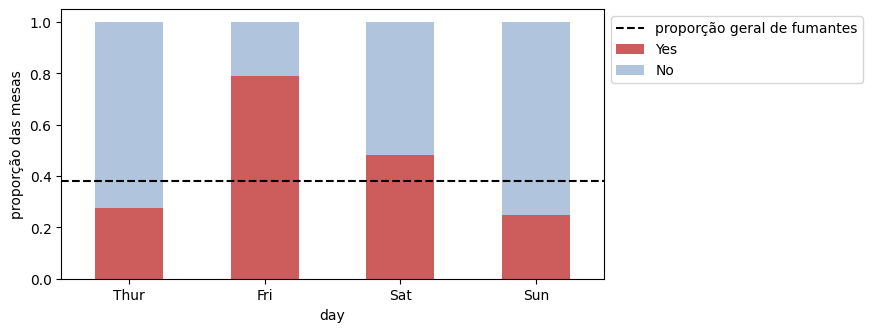

In [11]:
# Gráfico de barras empilhadas das proporções condicionais.
ax = por_dia.plot.bar(stacked=True, figsize=(7, 3.5), color=["indianred", "lightsteelblue"], rot=0)
ax.axhline(gorjetas["smoker"].eq("Yes").mean(), color="black", linestyle="--", label="proporção geral de fumantes")
ax.set_ylabel("proporção das mesas")
ax.legend(loc="upper left", bbox_to_anchor=(1, 1))   # bbox_to_anchor coloca a legenda fora do gráfico
plt.show()

**Conclusão:** a tabela cruzada revela uma relação fortíssima entre dia e refeição: no **sábado e no domingo só há jantares**, e na quinta quase só almoços (61 de 62 mesas). Nesses dados, saber o dia praticamente determina a refeição.

Nas proporções condicionais, a proporção de mesas com fumantes muda muito de dia para dia: **78,9%** na sexta, 48,3% no sábado, 27,4% na quinta e 25,0% no domingo, contra **38%** no geral (a linha tracejada). Mas lembre-se de que a sexta tem só **19 mesas** (15 delas com fumantes). Uma diferença tão grande num grupo tão pequeno pode ser real ou pode ser acaso, e só um **teste de hipótese** (notebook 12) permite decidir.

## 🎓 Conceito: correlação não é causalidade

Duas variáveis podem estar fortemente correlacionadas **sem que uma cause a outra**. O motivo mais comum é uma **variável de confusão** (*confounder*): uma terceira variável que influencia as duas.

O exemplo clássico: a venda de **sorvetes** e o número de **afogamentos** sobem e descem juntos. Sorvete causa afogamento? Não: os dois aumentam no **calor** (mais gente toma sorvete e mais gente vai nadar).

Vamos simular essa história.

In [12]:
rng = np.random.default_rng(42)
dias = 365
# A temperatura de cada dia (a variável de confusão).
temperatura = rng.normal(25, 6, dias)
# Sorvetes e afogamentos dependem SÓ da temperatura (mais um ruído); um não depende do outro.
sorvetes = 50 + 8 * temperatura + rng.normal(0, 25, dias)
afogamentos = rng.poisson(np.clip(0.15 * (temperatura - 10), 0, None))   # Poisson: contagens (notebook 07)

r_bruta = stats.pearsonr(sorvetes, afogamentos).statistic
print(f"Correlação sorvetes × afogamentos: {r_bruta:.2f}")

# Controlando pela temperatura: comparamos só dias com temperaturas parecidas (faixas de 2 graus).
faixa = pd.cut(temperatura, bins=np.arange(5, 46, 2))
dados = pd.DataFrame({"faixa": faixa, "sorvetes": sorvetes, "afogamentos": afogamentos})
# Dentro de cada faixa de temperatura, calculamos a correlação (só faixas com pelo menos 20 dias).
correlacoes = []
for intervalo, grupo in dados.groupby("faixa", observed=True):
    if len(grupo) >= 20:
        correlacoes.append(grupo["sorvetes"].corr(grupo["afogamentos"]))
        print(f"  temperatura {intervalo}: {len(grupo):3d} dias, correlação = {correlacoes[-1]:+.2f}")
print(f"Correlação média dentro das faixas: {np.mean(correlacoes):+.2f}")

Correlação sorvetes × afogamentos: 0.42
  temperatura (17, 19]:  30 dias, correlação = +0.09
  temperatura (19, 21]:  34 dias, correlação = -0.06
  temperatura (21, 23]:  46 dias, correlação = +0.34
  temperatura (23, 25]:  48 dias, correlação = +0.15
  temperatura (25, 27]:  55 dias, correlação = +0.05
  temperatura (27, 29]:  46 dias, correlação = +0.11
  temperatura (29, 31]:  32 dias, correlação = +0.09
Correlação média dentro das faixas: +0.11


**Conclusão:** sorvetes e afogamentos têm correlação **0,42**, mesmo que, na simulação, um **não tenha nenhum efeito** sobre o outro. Quando comparamos só dias de temperatura parecida (faixas de 2 graus), a correlação cai para valores entre −0,06 e +0,34, com média de **+0,11**. Ela não chega exatamente a zero porque, dentro de cada faixa, a temperatura ainda varia um pouco (e um pouco de ruído das amostras pequenas), mas a maior parte da relação **desaparece** quando "controlamos" a variável de confusão.

Num estudo real, nem sempre conhecemos (ou medimos) a variável de confusão. Por isso, para afirmar que algo **causa** outra coisa, o padrão-ouro são os **experimentos controlados** (como os testes A/B), em que o acaso decide quem recebe cada tratamento.

## 4. O paradoxo de Simpson

O caso mais extremo de variável de confusão é o **paradoxo de Simpson**: uma relação que aparece nos dados agrupados **se inverte** dentro de cada grupo. Vamos olhar o comprimento e a profundidade do bico dos pinguins.

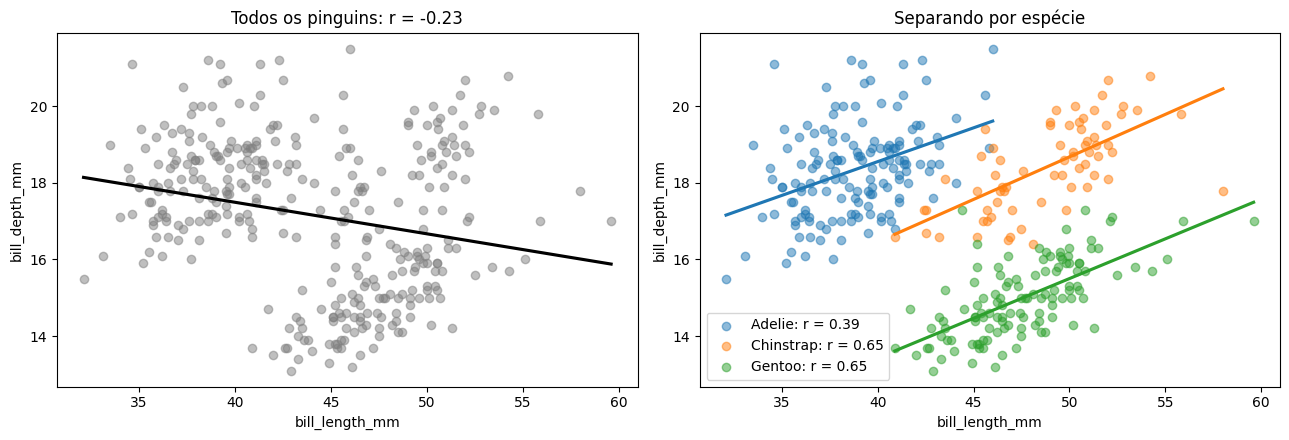

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# Esquerda: todos juntos, com uma reta de tendência (regplot ajusta e desenha a reta).
sns.regplot(data=pinguins, x="bill_length_mm", y="bill_depth_mm", ax=axes[0], ci=None,
            scatter_kws={"alpha": 0.5, "color": "gray"}, line_kws={"color": "black"})
r_geral = pinguins["bill_length_mm"].corr(pinguins["bill_depth_mm"])
axes[0].set_title(f"Todos os pinguins: r = {r_geral:.2f}")

# Direita: uma cor e uma reta por espécie.
for especie, grupo in pinguins.groupby("species"):
    r = grupo["bill_length_mm"].corr(grupo["bill_depth_mm"])
    sns.regplot(data=grupo, x="bill_length_mm", y="bill_depth_mm", ax=axes[1], ci=None,
                scatter_kws={"alpha": 0.5}, label=f"{especie}: r = {r:.2f}")
axes[1].set_title("Separando por espécie")
axes[1].legend()
plt.tight_layout()
plt.show()

**Conclusão:** com todos os pinguins juntos, a correlação entre comprimento e profundidade do bico é **−0,23**: a reta preta desce, sugerindo que bicos mais compridos são mais rasos. Mas, **dentro de cada espécie**, a relação é **positiva**: **0,39** nos Adelie e **0,65** nos Chinstrap e nos Gentoo. Bicos mais compridos são também mais profundos, como seria de esperar de pinguins maiores.

O que inverte a relação é a **espécie**: os Gentoo têm bicos compridos e **rasos**, e os Adelie, curtos e profundos. Misturar os grupos cria uma tendência que não existe em nenhum deles.

Quem só olhasse o gráfico da esquerda chegaria à conclusão **errada**. Diante de uma correlação, sempre vale perguntar: existe algum grupo escondido nos dados?

## 5. Resumo e próximos passos

| Tipos das variáveis | Gráfico | Medida |
|---|---|---|
| numérica × numérica | dispersão | covariância, Pearson (linear), Spearman (monotônica) |
| categórica × categórica | barras empilhadas | tabela de contingência, proporções condicionais |
| numérica × categórica | boxplot / violino por grupo | resumo por grupo (`groupby`) |

**Conceitos que você aprendeu**
- **Covariância** e por que ela depende das unidades.
- **Correlação de Pearson** (só relações **lineares**) e $r^2$.
- O **quarteto de Anscombe**: mesma correlação, relações completamente diferentes.
- **Correlação de Spearman** (relações monotônicas e robustez a outliers).
- **Tabelas de contingência** e proporções condicionais.
- **Correlação não é causalidade**, variáveis de confusão e o **paradoxo de Simpson**.

🔗 **Ponte para o ML:** no ML-01, atributos muito correlacionados entre si (cômodos e quartos) deixavam os coeficientes da regressão linear **instáveis** (a multicolinearidade, no notebook 09 de lá). E no ML-02, a seção de justiça (fairness) lembrou que um modelo aprende **correlações** dos dados, não causas.

**Python novo:** `ax.scatter`, `np.cov`, `stats.pearsonr` / `spearmanr` / `rankdata`, `.corr()`, `sns.heatmap`, `sns.lmplot` / `regplot`, `.groupby().apply`, `np.append`, `pd.crosstab` (com `margins` e `normalize`), gráficos de barras empilhadas, `np.clip`.

**Próximo notebook:** com isto terminamos a **estatística descritiva**. A partir do notebook 05 entramos na **probabilidade**: a matemática da incerteza, que explica por que as médias das amostras variam, por que a correlação de 19 mesas da sexta-feira é menos confiável, e como os modelos de ML expressam o que não sabem.